## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate, lagged_fit, lagged_evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# OPEN FOLDERS
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"
msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

ds = dfs.read(time = slice("2019-01-01", "2023-10-31"))

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
#hf = ["Drogden", "Klagshamn", "Dragor", "Barseback"]
# availabilities 97-50-98-50
#alllist = [s for s in alllist if s.name in hf]

# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(alllist, ds_time=ds.time, obs_fldr=obs_fldr)
measurements = torch.as_tensor(measurements, dtype=torch.float32)
print("IN:\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# print the shape of the arrays
print("OUT:\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes, dfs

IN:
Measurements shape: torch.Size([84720, 13])
OUT:
H shape: torch.Size([84720, 3320])
U shape: torch.Size([84720, 3320])
V shape: torch.Size([84720, 3320])


In [4]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_H = 15         # modes kept for H (surface elevation)
COMPRESS_U = 100         # modes kept for U (U velocity)
COMPRESS_V = 100         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Lagged-loss configuration
W_FACTOR = 0.7
W_KEEPED_TIMESTEPS = 16

# Architecture
ENCODER_DEPTH = 3               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64,96]     # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

# Persist every trained model checkpoint
MODEL_SAVE_DIR = Path("outputs") / "RUNL" / "models"
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

def save_model_checkpoint(model, model_name):
    model_path = MODEL_SAVE_DIR / f"{model_name}.pt"
    torch.save(model.state_dict(), model_path)
    print(f"Saved model checkpoint: {model_path}")

def load_model_checkpoint(model, model_name, map_location=device, eval_mode=True):
    model_path = MODEL_SAVE_DIR / f"{model_name}.pt"
    if not model_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {model_path}")

    state_dict = torch.load(model_path, map_location=map_location)
    model.load_state_dict(state_dict)
    model.to(map_location)
    if eval_mode:
        model.eval()
    print(f"Loaded model checkpoint: {model_path}")
    return model


## (T.3.F): Masking MHSA learned

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 215])

Input shape for the model: 13
Output shape for the model: 215


Starting training...


Training:  81%|████████  | 162/200 [52:13<12:14, 19.34s/it, Train Loss=0.00331, Val Loss=0.00369, Patience=39, Best Val Loss=0.00366, LR=4.10e-05]

Early stopping at epoch 163
Training completed with best validation loss: 0.0037
Saved model checkpoint: outputs/RUNL/models/T.3.F_masking_MHSA_learned.pt


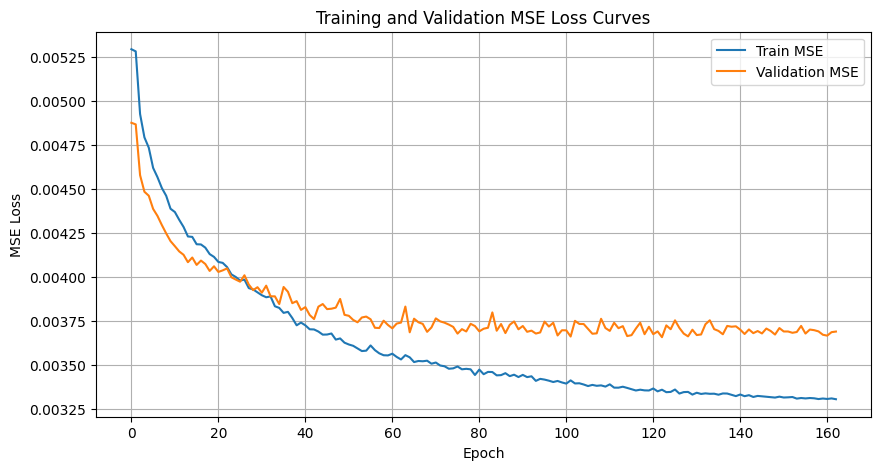

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.00336,0.003659,0.00392,0.129669,0.135717,0.137247


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshredA = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshredA, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )
save_model_checkpoint(mshredA, "T.3.F_masking_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshredA, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [7]:
del train_dataset, val_dataset, test_dataset

## (T.3.F.LAGGED): Masking MHSA learned

In [8]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, pad_output=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1] 
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 24, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 24, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 24, 215])

Input shape for the model: 13
Output shape for the model: 215


Lagged loss weights (W): 
[0.         0.         0.         0.         0.         0.
 0.         0.         0.00142902 0.00204145 0.00291636 0.00416623
 0.00595176 0.00850251 0.01214645 0.01735207 0.02478867 0.03541239
 0.05058913 0.07227018 0.10324311 0.14749016 0.21070021 0.30100033]
Starting training...


Training:  66%|██████▋   | 133/200 [1:37:38<49:11, 44.05s/it, Train Loss=0.00330, Val Loss=0.00371, Patience=39, Best Val Loss=0.00367, LR=1.23e-04]  

Early stopping at epoch 134
Training completed with best validation loss: 0.0037
Saved model checkpoint: outputs/RUNL/models/T.3.F.LAGGED_masking_MHSA_learned.pt


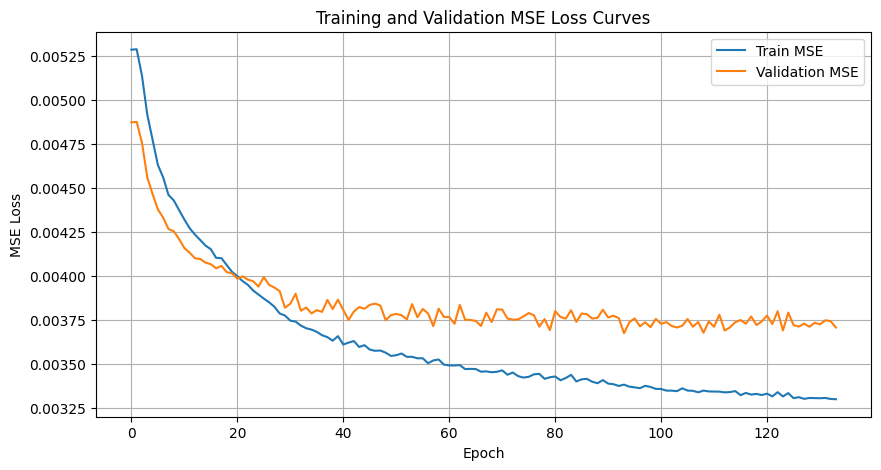

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003360,0.003659,0.003920,0.129669,0.135717,0.137247
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003383,0.003675,0.003969,0.130203,0.136018,0.137792


In [9]:
# Lagged training configuration for 3D decoder
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
    decoder_3D=True,
)
mshredB = mSHRED(args=model_args).to(device)

train_errors, valid_errors = lagged_fit(
    mshredB, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE, w_factor=W_FACTOR, w_keeped_steps=W_KEEPED_TIMESTEPS,
)
save_model_checkpoint(mshredB, "T.3.F.LAGGED_masking_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    lagged_evaluate, mshredB, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type=f"(T.3.F.LAGGED): masking MHSA learned (w={W_FACTOR}, k={W_KEEPED_TIMESTEPS})",
    masking_type=MASKING_TYPE,
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


In [10]:
del train_dataset, val_dataset, test_dataset

## (T.3.G): Masking x2 channels + MHSA learned

In [11]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 215])

Input shape for the model: 13
Output shape for the model: 215


Starting training...


Training:  67%|██████▋   | 134/200 [46:16<22:47, 20.72s/it, Train Loss=0.00335, Val Loss=0.00374, Patience=39, Best Val Loss=0.00366, LR=1.19e-04]

Early stopping at epoch 135
Training completed with best validation loss: 0.0037
Saved model checkpoint: outputs/RUNL/models/T.3.G_masking_x2_channels_MHSA_learned.pt


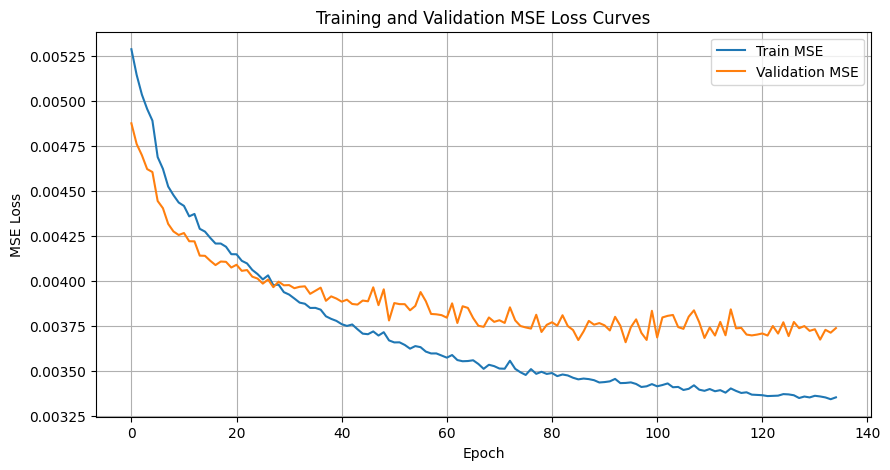

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003360,0.003659,0.003920,0.129669,0.135717,0.137247
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003383,0.003675,0.003969,0.130203,0.136018,0.137792
2,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003434,0.003660,0.004035,0.131141,0.135949,0.139273


In [12]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshredC = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshredC, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )
save_model_checkpoint(mshredC, "T.3.G_masking_x2_channels_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshredC, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [13]:
del train_dataset, val_dataset, test_dataset

## (T.3.G.LAGGED): Masking x2 channels + MHSA learned


In [14]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, pad_output=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1] 
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 24, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 24, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 24, 215])

Input shape for the model: 13
Output shape for the model: 215


Lagged loss weights (W): 
[0.         0.         0.         0.         0.         0.
 0.         0.         0.00142902 0.00204145 0.00291636 0.00416623
 0.00595176 0.00850251 0.01214645 0.01735207 0.02478867 0.03541239
 0.05058913 0.07227018 0.10324311 0.14749016 0.21070021 0.30100033]
Starting training...


Training:  90%|█████████ | 180/200 [2:11:53<14:39, 43.96s/it, Train Loss=0.00328, Val Loss=0.00371, Patience=39, Best Val Loss=0.00363, LR=1.11e-05]  

Early stopping at epoch 181
Training completed with best validation loss: 0.0036
Saved model checkpoint: outputs/RUNL/models/T.3.G.LAGGED_masking_x2_channels_MHSA_learned.pt


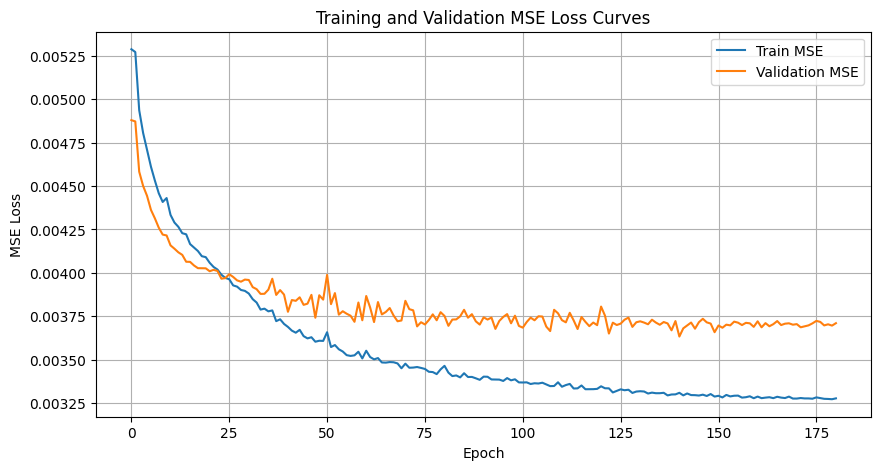

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003360,0.003659,0.003920,0.129669,0.135717,0.137247
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003383,0.003675,0.003969,0.130203,0.136018,0.137792
2,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003434,0.003660,0.004035,0.131141,0.135949,0.139273
3,(mSHRED): TR+cnn,(T.3.G.LAGGED): masking x2 channels + MHSA lea...,0.003308,0.003633,0.003959,0.128898,0.135386,0.137837


In [15]:
# Lagged training configuration for 3D decoder with x2 channels
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
    decoder_3D=True,
)
mshredD = mSHRED(args=model_args).to(device)

train_errors, valid_errors = lagged_fit(
    mshredD, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE, w_factor=W_FACTOR, w_keeped_steps=W_KEEPED_TIMESTEPS,
)
save_model_checkpoint(mshredD, "T.3.G.LAGGED_masking_x2_channels_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    lagged_evaluate, mshredD, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type=f"(T.3.G.LAGGED): masking x2 channels + MHSA learned (w={W_FACTOR}, k={W_KEEPED_TIMESTEPS})",
    masking_type=MASKING_TYPE,
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


In [16]:
del train_dataset, val_dataset, test_dataset

## Results

In [17]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003360,0.003659,0.003920,0.129669,0.135717,0.137247
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003383,0.003675,0.003969,0.130203,0.136018,0.137792
2,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003434,0.003660,0.004035,0.131141,0.135949,0.139273
3,(mSHRED): TR+cnn,(T.3.G.LAGGED): masking x2 channels + MHSA lea...,0.003308,0.003633,0.003959,0.128898,0.135386,0.137837


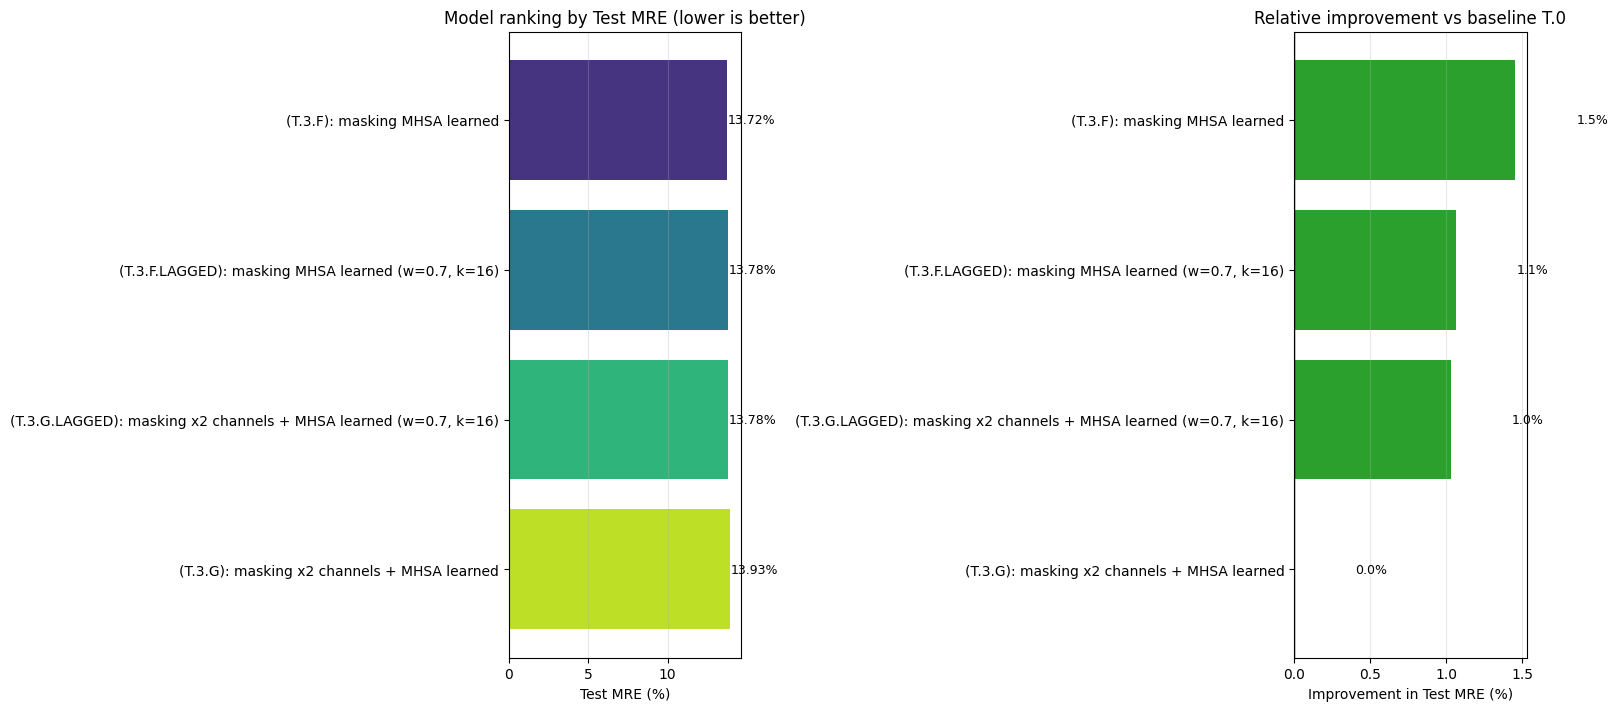

In [18]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()